<a href="https://colab.research.google.com/github/Pooja-Naik7799/DSA-Java/blob/main/ANN_practical_implemention.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
!pip install tensorflow

In [10]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [11]:
#import some basic libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [12]:
dataset=pd.read_csv('Churn_Modelling.csv')
dataset.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [13]:
#diving the datset into two features
X=dataset.iloc[:,3:13]
y=dataset.iloc[:,13]

In [14]:
X.head()
y

,Exited
0,1
1,0
2,1
3,0
4,0
...,...
9995,0
9996,0
9997,1
9998,1


In [15]:
#feature engineering
geography=pd.get_dummies(X['Geography'],drop_first=True)
gender=pd.get_dummies(X['Gender'],drop_first=True)


In [16]:
X.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10


In [20]:
X = X.drop(['Geography', 'Gender'], axis=1)
X=pd.concat([X,geography,gender],axis=1)

In [22]:
#splitting dataset inot traning and test ste
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=0)

In [23]:
#feature scaling
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)

In [24]:
X_train

array([[ 0.16958176, -0.46460796,  0.00666099, ..., -0.5698444 ,
         1.74309049, -1.09168714],
       [-2.30455945,  0.30102557, -1.37744033, ...,  1.75486502,
        -0.57369368,  0.91601335],
       [-1.19119591, -0.94312892, -1.031415  , ..., -0.5698444 ,
        -0.57369368, -1.09168714],
       ...,
       [ 0.9015152 , -0.36890377,  0.00666099, ..., -0.5698444 ,
        -0.57369368,  0.91601335],
       [-0.62420521, -0.08179119,  1.39076231, ..., -0.5698444 ,
         1.74309049, -1.09168714],
       [-0.28401079,  0.87525072, -1.37744033, ...,  1.75486502,
        -0.57369368, -1.09168714]])

In [25]:
X_train.shape

(8000, 11)

In [34]:
##part 2 now elets create the ann
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LeakyReLU,PReLU,ELU,ReLU
from tensorflow.keras.layers import Dropout


In [28]:
#lets initial the ann
classifier=Sequential()

In [29]:
#adding the i/p layer
classifier.add(Dense(units=11,activation='relu'))

In [30]:
#adding the first hidden layer
classifier.add(Dense(units=7,activation='relu'))

In [31]:
classifier.add(Dense(units=6,activation='relu'))

In [35]:
#adding the o/p layer
classifier.add(Dense(1,activation='sigmoid'))

In [36]:
classifier.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [40]:
#early stopping
import tensorflow as tf

early_stopping=tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    min_delta=0.0001,
    patience=20,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False,
    start_from_epoch=0,
)

In [41]:
model_history=classifier.fit(X_train,y_train,validation_split=0.33,batch_size=10,epochs=1000,callbacks=early_stopping)

Epoch 1/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8716 - loss: 0.3159 - val_accuracy: 0.8523 - val_loss: 0.3640
Epoch 2/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8720 - loss: 0.3156 - val_accuracy: 0.8474 - val_loss: 0.3653
Epoch 3/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8733 - loss: 0.3159 - val_accuracy: 0.8512 - val_loss: 0.3676
Epoch 4/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8716 - loss: 0.3162 - val_accuracy: 0.8478 - val_loss: 0.3666
Epoch 5/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8703 - loss: 0.3156 - val_accuracy: 0.8466 - val_loss: 0.3661
Epoch 6/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8735 - loss: 0.3147 - val_accuracy: 0.8497 - val_loss: 0.3648
Epoch 7/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8712 - loss: 0.3161 - val_accuracy: 0.8485 - val_loss: 0.3658
Epoch 8/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8735 - loss: 0.3153 - 

In [46]:
model_history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

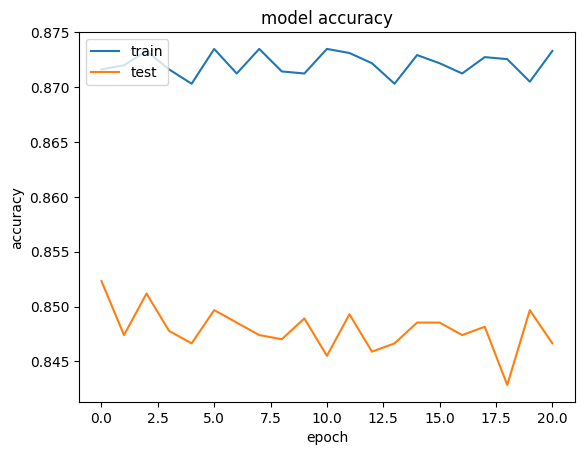

In [47]:
plt.plot(model_history.history['accuracy'])
plt.plot(model_history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train','test'],loc='upper left')
plt.show()

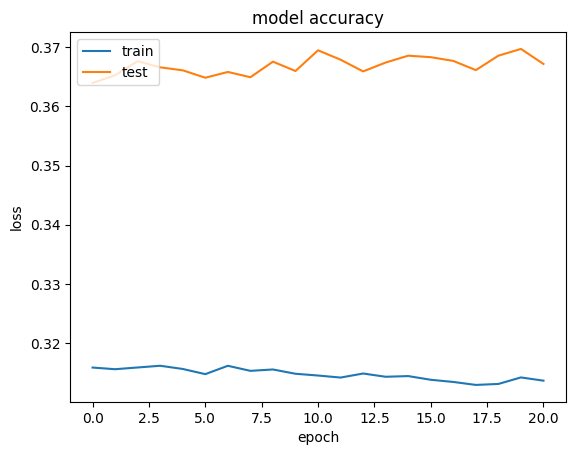

In [48]:
plt.plot(model_history.history['loss'])
plt.plot(model_history.history['val_loss'])
plt.title('model accuracy')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train','test'],loc='upper left')
plt.show()

In [49]:
y_pred=classifier.predict(X_test)
y_pred=(y_pred>0.5)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


In [50]:
#make the confucsion matrix
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
cm

array([[1502,   93],
       [ 209,  196]])

In [51]:
#cal accurracy
from sklearn.metrics import accuracy_score
score=accuracy_score(y_pred,y_test)

In [52]:
score

0.849

In [54]:
##get weightts
classifier.get_weights()

[array([[-0.01467771, -0.26709163,  0.00794389, -0.3221382 , -0.42028823,
          0.4294511 ,  0.3389504 ,  0.23468357,  0.0077292 , -0.01402643,
         -0.00585631],
        [ 0.1568935 ,  0.49846414,  0.05232739,  0.04003496,  1.1391269 ,
          0.2955909 , -1.000096  ,  1.0007391 , -0.15460756, -0.26614186,
         -0.7698272 ],
        [-0.09460256, -0.1742619 , -0.07768755,  0.5195561 , -0.26189235,
          0.38519174,  0.17140222,  0.19371831,  0.20415537, -0.04721927,
         -0.25965843],
        [ 0.25032023,  0.07803715, -0.20364308,  0.34954542, -0.23861744,
         -0.47406334, -0.75146407, -0.45532015,  0.04420356, -0.5007558 ,
         -0.11655519],
        [ 1.0464721 , -0.7681383 ,  0.06585712, -0.21983923, -0.04312837,
         -0.22786096,  0.14529227, -0.16604692,  0.6912536 , -1.263229  ,
          0.16000535],
        [ 0.12326115, -0.06306172,  0.64853257, -0.39310238, -0.32176468,
          0.3156449 , -0.5663485 , -0.04436802, -0.6992723 ,  0.3172266